In [ ]:
import warnings
warnings.filterwarnings('ignore', category=DeprecationWarning)

import numpy as np
import pandas as pd

In [ ]:
data = pd.read_csv("lastfm.csv")
data[0:18]

,user,artist,sex,country
0,1,red hot chili peppers,f,Germany
1,1,the black dahlia murder,f,Germany
2,1,goldfrapp,f,Germany
3,1,dropkick murphys,f,Germany
4,1,le tigre,f,Germany
5,1,schandmaul,f,Germany
6,1,edguy,f,Germany
7,1,jack johnson,f,Germany
8,1,eluveitie,f,Germany
9,1,the killers,f,Germany


In [ ]:
data.shape

(289955, 4)

In [ ]:
data.country.value_counts().sort_values(ascending = False)[0:20]

,count
country,
United States,59558
United Kingdom,27638
Germany,24251
Poland,17111
Sweden,12379
Brazil,11922
Russian Federation,11676
Finland,10157
Netherlands,9673


In [ ]:
data = data[(data.country == 'United States') | (data.country == 'Brazil') | (data.country == 'France')]
print(data.shape)
data.head()

(77442, 4)


,user,artist,sex,country
16,3,devendra banhart,m,United States
17,3,boards of canada,m,United States
18,3,cocorosie,m,United States
19,3,aphex twin,m,United States
20,3,animal collective,m,United States


In [ ]:
groupped = data.groupby('user')['artist'].apply(';'.join)
groupped

,artist
user,
3,devendra banhart;boards of canada;cocorosie;ap...
9,arch enemy;strapping young lad;kreator;childre...
18,sonata arctica;infected mushroom;iron maiden;c...
20,of montreal;the magnetic fields;devo;talking h...
32,nick cave and the bad seeds;black flag;the gos...
...,...
19682,the beatles;rihanna;good charlotte;aerosmith;e...
19691,nine inch nails;the smashing pumpkins;mindless...
19701,placebo;animal collective;crystal castles;brok...


In [ ]:
binary_data = groupped.str.get_dummies(";")
binary_data.iloc[0:10, 100:110]

,beastie boys,beatsteaks,beck,bee gees,behemoth,beirut,belle and sebastian,ben folds,ben folds five,ben harper
user,,,,,,,,,,
3,1,0,0,0,0,0,0,0,0,0
9,0,0,0,0,0,0,0,0,0,0
18,0,0,0,0,0,0,0,0,0,0
20,0,0,1,0,0,1,0,0,0,0
32,0,0,0,0,0,0,0,0,0,0
44,1,0,1,0,0,0,1,1,0,0
45,0,0,1,0,0,0,0,0,0,0
46,0,0,0,0,0,0,0,0,0,0
55,0,0,0,0,0,0,0,0,0,0


In [ ]:
binary_data.apply(sum, axis = 1).describe()

,0
count,3862.000000
mean,20.052305
std,10.516245
min,1.000000
25%,11.000000
50%,19.000000
75%,28.000000
max,63.000000


In [ ]:
countries = ['United States', 'France', 'Brazil']
def make_pvt(country):
    sub = data[data.country == country]
    pvt = (sub[['user', 'artist']].pivot_table(index='user', columns='artist', aggfunc=any, fill_value=False).astype(int))
    return pvt

pvts = {c: make_pvt(c) for c in countries}
for c, p in pvts.items():
    print(c, p.shape)

United States (2905, 992)
France (327, 901)
Brazil (630, 926)


In [ ]:
import mlxtend.frequent_patterns as ml

In [ ]:
freq_items = ml.apriori(binary_data, min_support = 0.05, use_colnames = True)
print("Найдено %d характерных комбинаций" % len(freq_items))
freq_items.sort_values(by = 'support')

Найдено 93 характерных комбинаций


,support,itemsets
14,0.050751,(brand new)
47,0.050751,(neutral milk hotel)
50,0.050751,(oasis)
83,0.050751,"(radiohead, beck)"
36,0.051010,(jay-z)
...,...,...
53,0.119109,(pink floyd)
23,0.146038,(death cab for cutie)
20,0.158208,(coldplay)
57,0.224754,(radiohead)


In [ ]:
def get_freq(pvt, min_support=0.05):
    return ml.apriori(pvt, min_support=min_support, use_colnames=True)

freq = {c: get_freq(pvts[c], min_support=0.05) for c in countries}

for c in countries:
    print(f"Найдено {len(freq[c])} характерных комбинаций в {c}")
    print(freq[c],'\n')

Найдено 106 характерных комбинаций в United States
      support                     itemsets
0    0.058176                        (air)
1    0.059552                (andrew bird)
2    0.079862          (animal collective)
3    0.074010                (arcade fire)
4    0.067126               (beastie boys)
..        ...                          ...
101  0.052668    (the beatles, pink floyd)
102  0.056454  (sufjan stevens, radiohead)
103  0.100172     (the beatles, radiohead)
104  0.058520       (the shins, radiohead)
105  0.055766     (the beatles, the shins)

[106 rows x 2 columns] 

Найдено 91 характерных комбинаций в France
     support                            itemsets
0   0.061162                             (ac/dc)
1   0.140673                               (air)
2   0.061162                        (amon tobin)
3   0.088685                     (amy winehouse)
4   0.076453                       (arcade fire)
..       ...                                 ...
86  0.051988         

In [ ]:
def top_singles(fi, n=5):
    s = fi[fi.itemsets.apply(len) == 1].copy()
    s['artist'] = s.itemsets.apply(lambda x: list(x)[0])
    return s.sort_values('support', ascending=False).head(n)[['artist', 'support']]

for c in countries:
    print(f"\n Топ групп в {c}")
    print(top_singles(freq[c], 5).to_string(index=False))


 Топ групп в United States
             artist  support
        the beatles 0.270568
          radiohead 0.230981
death cab for cutie 0.176592
           coldplay 0.153873
       modest mouse 0.142513

 Топ групп в France
     artist  support
  radiohead 0.269113
       muse 0.168196
 pink floyd 0.168196
   coldplay 0.162080
the beatles 0.162080

 Топ групп в Brazil
       artist  support
  the beatles 0.255556
 los hermanos 0.201587
amy winehouse 0.180952
     coldplay 0.176190
    radiohead 0.173016


# Алгоритмы поиска характерных комбинаций для USA


In [ ]:
pvt_us = pvts['United States']

ap = ml.apriori(pvt_us, min_support=0.05, use_colnames=True)
fp = ml.fpgrowth(pvt_us, min_support=0.05, use_colnames=True)
fpmax = ml.fpmax(pvt_us, min_support=0.05, use_colnames=True)
hm = ml.hmine(pvt_us, min_support=0.05, use_colnames=True)

print("apriori :", len(ap))
print("fpgrowth:", len(fp))
print("fpmax   :", len(fpmax))
print("hmine   :", len(hm))

apriori : 106
fpgrowth: 106
fpmax   : 95
hmine   : 106


# Алгоритмы поиска характерных комбинаций для France


In [ ]:
pvt_fr = pvts['France']

ap = ml.apriori(pvt_fr, min_support=0.05, use_colnames=True)
fp = ml.fpgrowth(pvt_fr, min_support=0.05, use_colnames=True)
fpmax = ml.fpmax(pvt_fr, min_support=0.05, use_colnames=True)
hm = ml.hmine(pvt_fr, min_support=0.05, use_colnames=True)

print("apriori :", len(ap))
print("fpgrowth:", len(fp))
print("fpmax   :", len(fpmax))
print("hmine   :", len(hm))

apriori : 91
fpgrowth: 91
fpmax   : 72
hmine   : 91


# Алгоритмы поиска характерных комбинаций для Brazil


Здесь я намеренно ставлю низкий min_support для Apriori, чтобы получить правила, длиной больше 5

In [ ]:
pvt_br = pvts['Brazil']

ap = ml.apriori(pvt_br, min_support=0.01, use_colnames=True)
fp = ml.fpgrowth(pvt_br, min_support=0.05, use_colnames=True)
fpmax = ml.fpmax(pvt_br, min_support=0.05, use_colnames=True)
hm = ml.hmine(pvt_br, min_support=0.05, use_colnames=True)

print("apriori :", len(ap))
print("fpgrowth:", len(fp))
print("fpmax   :", len(fpmax))
print("hmine   :", len(hm))

apriori : 5387
fpgrowth: 117
fpmax   : 103
hmine   : 117


# Оценка правил с помощью Jaccard для Brazil


In [ ]:
rules_ap = ml.association_rules(ap, metric="confidence", min_threshold=0.3)
rules_ap['jaccard'] = rules_ap.eval(
    'support / (`antecedent support` + `consequent support` - support)'
)
print(rules_ap.nlargest(10, 'jaccard')[
    ['antecedents', 'consequents', 'support', 'jaccard', 'confidence', 'lift']
])

                                             antecedents  \
10405  (rihanna, the pussycat dolls, avril lavigne, b...   
10407                  (paramore, gwen stefani, rihanna)   
10426       (the pussycat dolls, avril lavigne, beyoncé)   
10428                           (paramore, gwen stefani)   
9811        (the pussycat dolls, avril lavigne, beyoncé)   
9812                            (paramore, gwen stefani)   
10412       (paramore, gwen stefani, the pussycat dolls)   
10421                  (rihanna, avril lavigne, beyoncé)   
7865                             (rihanna, gwen stefani)   
7870                 (the pussycat dolls, avril lavigne)   

                                             consequents   support   jaccard  \
10405                           (paramore, gwen stefani)  0.011111  0.636364   
10407       (the pussycat dolls, avril lavigne, beyoncé)  0.011111  0.636364   
10426                  (paramore, gwen stefani, rihanna)  0.011111  0.636364   
10428  (rihanna, th

In [ ]:
rules_fpg = ml.association_rules(fp, metric="confidence", min_threshold=0.3)
rules_fpg['jaccard'] = rules_fpg.eval(
    'support / (`antecedent support` + `consequent support` - support)'
)
print(rules_fpg.nlargest(10, 'jaccard')[
    ['antecedents', 'consequents', 'support', 'jaccard', 'confidence', 'lift']
])

         antecedents       consequents   support   jaccard  confidence  \
25     (the strokes)       (radiohead)  0.069841  0.287582    0.500000   
26       (radiohead)     (the strokes)  0.069841  0.287582    0.403670   
8     (led zeppelin)      (pink floyd)  0.053968  0.283333    0.478873   
9       (pink floyd)    (led zeppelin)  0.053968  0.283333    0.409639   
27  (arctic monkeys)     (the strokes)  0.060317  0.262069    0.400000   
28     (the strokes)  (arctic monkeys)  0.060317  0.262069    0.431818   
16    (los hermanos)       (radiohead)  0.077778  0.262032    0.385827   
17       (radiohead)    (los hermanos)  0.077778  0.262032    0.449541   
11  (arctic monkeys)     (the killers)  0.052381  0.250000    0.347368   
12     (the killers)  (arctic monkeys)  0.052381  0.250000    0.471429   

        lift  
25  2.889908  
26  2.889908  
8   3.634821  
9   3.634821  
27  2.863636  
28  2.863636  
16  2.230008  
17  2.230008  
11  3.126316  
12  3.126316  


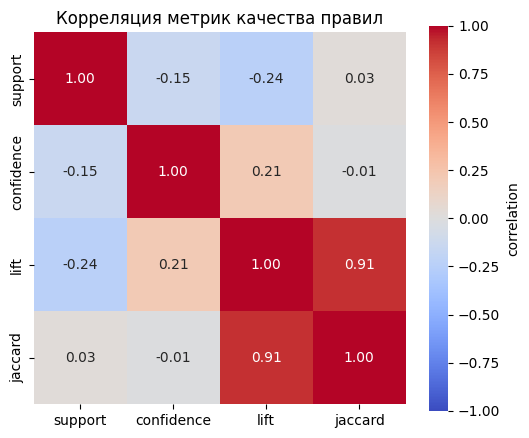

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = rules[['support', 'confidence', 'lift', 'jaccard']].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr,
            annot=True,
            fmt='.2f',
            cmap='coolwarm',
            vmin=-1, vmax=1,
            square=True,
            cbar_kws={'label': 'correlation'})
plt.title('Корреляция метрик качества правил')
plt.show()

# Наборы и правила длиной больше 5
Для данного условия я поставил min_support для Apriori на 0.01.

Один из наборов: **'the killers', 'the strokes', 'radiohead', 'franz ferdinand', 'the beatles'**

А из правил можем взять: **paramore, gwen stefani, rihanna -> the pussycat dolls, avril lavigne, beyoncé**

In [ ]:
freq_long = ap[ap.itemsets.apply(len) >= 5]
print(f"Наборов длины ≥5: {len(freq_long)}")
freq_long.sort_values('support', ascending=False).head(10)

Наборов длины ≥5: 43


,support,itemsets
5381,0.014286,"(the killers, the strokes, radiohead, franz fe..."
5352,0.012698,"(the strokes, radiohead, franz ferdinand, the ..."
5353,0.012698,"(the killers, the strokes, radiohead, franz fe..."
5363,0.012698,"(paramore, rihanna, beyoncé, the pussycat doll..."
5373,0.012698,"(paramore, rihanna, beyoncé, the pussycat doll..."
5379,0.012698,"(los hermanos, the killers, the strokes, radio..."
5382,0.012698,"(the white stripes, the strokes, radiohead, fr..."
5362,0.012698,"(rihanna, gwen stefani, beyoncé, the pussycat ..."
5368,0.012698,"(paramore, rihanna, gwen stefani, the pussycat..."
5356,0.012698,"(oasis, the strokes, radiohead, the beatles, a..."


# Тривиальные правила

In [ ]:
trivial = rules_fpg[(rules_fpg.lift < 1.5)]
trivial

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
13,(coldplay),(the beatles),0.176190,0.255556,0.063492,0.360360,1.410106,1.0,0.018466,1.163850,0.353035,0.172414,0.140783,0.304404
36,(amy winehouse),(the beatles),0.180952,0.255556,0.065079,0.359649,1.407323,1.0,0.018836,1.162557,0.353375,0.175214,0.139827,0.307154


Например, связь Amy Winehouse -> The Beatles можно назвать тривиальной.

Например, связь Coldplay -> The Beatles можно назвать тривиальной.

Тут роль играют The Beatles, так как их слушает самое разнообразное сообщество людей, ведь The Beatles является классикой жанра.

# Нетривиальные правила

**(los hermanos) → (radiohead)** является нетривиальной парой, так как первые являются бразильским инди, а Radiohead британским альт-роком.

# Сравнение коротких правил с длинными

Как пример возьмем:

*   paramore, gwen stefani, rihanna -> the pussycat dolls, avril lavigne, beyoncé
*   the strokes -> radiohead

Для длинного примера Lift равен 55.12, тогда как для короткого это 2.88.

Для длинного примера Jaccard равен 0.63, тогда как для короткого это 0.28.

Support у короткого выше.

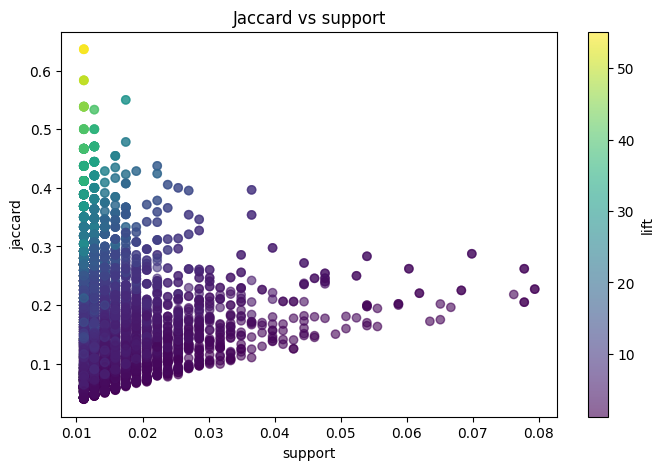

In [ ]:

plt.figure(figsize=(8,5))
plt.scatter(rules_ap['support'], rules_ap['jaccard'],
            c=rules['lift'], cmap='viridis', alpha=0.6)
plt.colorbar(label='lift')
plt.xlabel('support'); plt.ylabel('jaccard')
plt.title('Jaccard vs support')
plt.show()

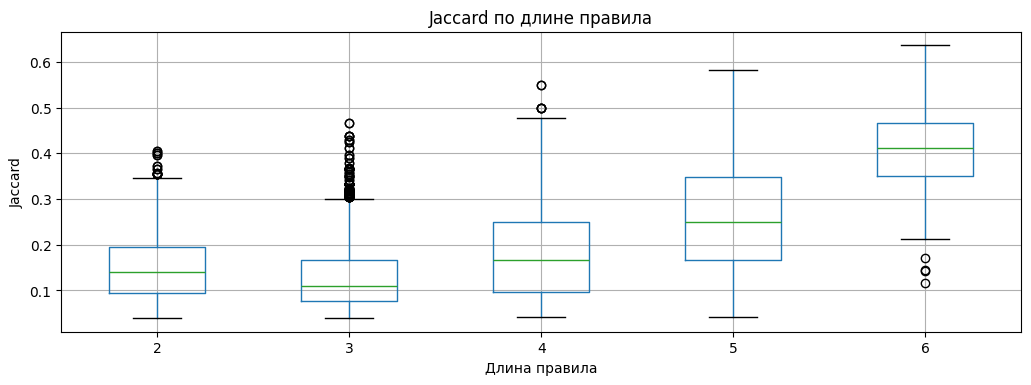

In [ ]:
rules_ap = rules_ap.copy()
rules_ap['rule_len'] = rules_ap.antecedents.apply(len) + rules_ap.consequents.apply(len)

fig, ax = plt.subplots(figsize=(12, 4))

rules_ap.boxplot(column='jaccard', by='rule_len', ax=ax)
ax.set_title('Jaccard по длине правила')
ax.set_xlabel('Длина правила')
ax.set_ylabel('Jaccard')

plt.suptitle('')
plt.show()